<a href="https://colab.research.google.com/github/surakshyakarkii/MTA-Bus-Speeds-Analysis/blob/main/MTA_Team_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Team 4: Assignment 2

In [ ]:

import zipfile
import glob

zip_files = glob.glob("MTA-Bus-Speeds-Analysis/MTA_Central_Business_District_Bus_Speeds__Beginning_2023_20260929.zip", recursive=True)
# Open ZIP file
with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/mta_data")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import pandas as pd

csv_files = glob.glob("/content/mta_data/**/*.csv", recursive=True)

df = pd.read_csv(csv_files[0])
df.head()

,Month,Day Type,Hour of Day,TIme Period,Route Type,Route ID,CBD Relation,Sum Mileage,Sum Time,Average Road Speed
0,12/01/2025,Weekday,0,Overnight,Express,BM1,Non-CBD,53.79,4.26,12.63
1,12/01/2025,Weekday,0,Overnight,Express,BM2,CBD,289.33,22.25,13.01
2,12/01/2025,Weekday,0,Overnight,Express,BM2,Non-CBD,135.75,13.24,10.25
3,12/01/2025,Weekday,0,Overnight,Express,BM3,CBD,102.76,4.49,22.86
4,12/01/2025,Weekday,0,Overnight,Express,BM3,Non-CBD,93.69,7.06,13.27


## Data Understanding

In [ ]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (670748, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670748 entries, 0 to 670747
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Month               670748 non-null  object 
 1   Day Type            670748 non-null  object 
 2   Hour of Day         670748 non-null  int64  
 3   TIme Period         670748 non-null  object 
 4   Route Type          670748 non-null  object 
 5   Route ID            670748 non-null  object 
 6   CBD Relation        670748 non-null  object 
 7   Sum Mileage         670748 non-null  object 
 8   Sum Time            670748 non-null  float64
 9   Average Road Speed  670748 non-null  float64
dtypes: float64(2), int64(1), object(7)
memory usage: 51.2+ MB


In [ ]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Month                 0
Day Type              0
Hour of Day           0
TIme Period           0
Route Type            0
Route ID              0
CBD Relation          0
Sum Mileage           0
Sum Time              0
Average Road Speed    0
dtype: int64
Duplicate rows: 0


In [ ]:
df["Sum Mileage"].head(10)

,Sum Mileage
0,53.79
1,289.33
2,135.75
3,102.76
4,93.69
5,67.83
6,204.92
7,77.60
8,242.56
9,32.38


In [ ]:
# mileage was text because of commas
df["Sum Mileage"] = pd.to_numeric(
    df["Sum Mileage"].str.replace(",", ""),
    errors="coerce"
)

In [ ]:
print(df["Sum Mileage"].dtype)

float64


In [ ]:
df.describe()

,Hour of Day,Sum Mileage,Sum Time,Average Road Speed
count,670748.000000,670748.000000,670748.000000,670748.000000
mean,12.413125,596.644422,71.992009,9.638251
std,6.443951,624.121833,81.652292,3.870136
min,0.000000,0.230000,0.010000,1.510000
25%,7.000000,177.630000,17.950000,6.980000
50%,13.000000,380.950000,41.815000,8.850000
75%,18.000000,798.112500,93.960000,11.280000
max,23.000000,7560.360000,744.970000,57.300000


## Descriptive Statistics & Summarization

In [ ]:
columns = ["Sum Mileage", "Sum Time", "Average Road Speed"]

for col in columns:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Range:", df[col].max() - df[col].min())
    print("Variance:", df[col].var())
    print("Standard deviation:", df[col].std())


 Sum Mileage
Mean: 596.6444221973081
Median: 380.95
Mode: 53.26
Range: 7560.13
Variance: 389528.0619255897
Standard deviation: 624.1218325980831

 Sum Time
Mean: 71.99200899592694
Median: 41.815
Mode: 6.15
Range: 744.96
Variance: 6667.096739957561
Standard deviation: 81.65229170058585

 Average Road Speed
Mean: 9.638251399929628
Median: 8.85
Mode: 7.19
Range: 55.79
Variance: 14.977955059092448
Standard deviation: 3.870136310143668


In [ ]:
correlation = df[columns].corr()

print(correlation)

                    Sum Mileage  Sum Time  Average Road Speed
Sum Mileage            1.000000  0.908796           -0.034719
Sum Time               0.908796  1.000000           -0.307693
Average Road Speed    -0.034719 -0.307693            1.000000


In [ ]:
df.describe(include="object")

,Month,Day Type,TIme Period,Route Type,Route ID,CBD Relation
count,670748,670748,670748,670748,670748,670748
unique,44,2,2,6,354,2
top,06/01/2025,Weekday,Peak,Local,M101,Non-CBD
freq,15793,376847,457606,455025,5611,540715


In [ ]:
df["Month"] = pd.to_datetime(df["Month"])

print("First month:", df["Month"].min())
print("Last month:", df["Month"].max())

First month: 2023-01-01 00:00:00
Last month: 2026-08-01 00:00:00


In [ ]:
# Select numerical columns
columns = ["Sum Mileage", "Sum Time", "Average Road Speed"]

df[columns].describe()

,Sum Mileage,Sum Time,Average Road Speed
count,670748.000000,670748.000000,670748.000000
mean,596.644422,71.992009,9.638251
std,624.121833,81.652292,3.870136
min,0.230000,0.010000,1.510000
25%,177.630000,17.950000,6.980000
50%,380.950000,41.815000,8.850000
75%,798.112500,93.960000,11.280000
max,7560.360000,744.970000,57.300000


In [ ]:
# marking weekends as 1 and weekdays as 0
df["Is Weekend"] = (df["Day Type"] == "Weekend").astype(int)

# marking busy morning and evening hours as 1
df["Rush Hour"] = df["Hour of Day"].isin([7, 8, 9, 16, 17, 18]).astype(int)

# taking the year from the Month column
df["Year"] = df["Month"].dt.year

# checking the three new columns
df[["Is Weekend", "Rush Hour", "Year"]].head()

,Is Weekend,Rush Hour,Year
0,0,0,2025
1,0,0,2025
2,0,0,2025
3,0,0,2025
4,0,0,2025


In [ ]:
df.groupby("Day Type")["Average Road Speed"].mean()

,Average Road Speed
Day Type,
Weekday,9.727578
Weekend,9.523715


In [ ]:
hourly_speed = df.groupby("Hour of Day")["Average Road Speed"].mean()

hourly_speed

,Average Road Speed
Hour of Day,
0,11.010643
1,11.400386
2,11.805792
3,12.069363
4,12.041171
5,12.209690
6,11.408611
7,10.277595
8,9.688922


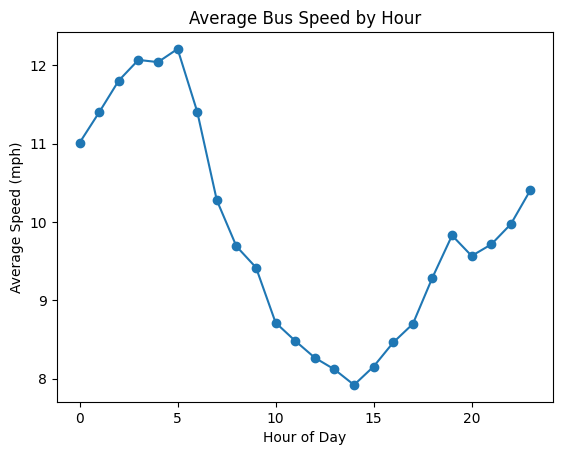

In [ ]:
import matplotlib.pyplot as plt

hourly_speed.plot(kind="line", marker="o")

plt.title("Average Bus Speed by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Speed (mph)")

plt.show()

Data Distributions

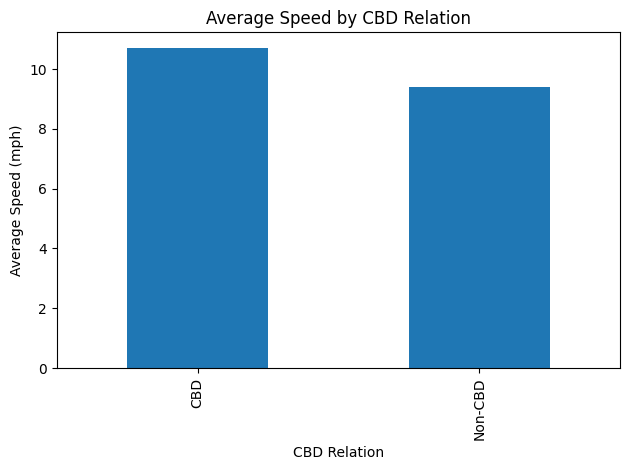

In [ ]:
# Compare CBD speeds
cbd_speed = df.groupby("CBD Relation")["Average Road Speed"].mean()

cbd_speed.plot(kind="bar")
plt.title("Average Speed by CBD Relation")
plt.ylabel("Average Speed (mph)")
plt.tight_layout()

plt.show()

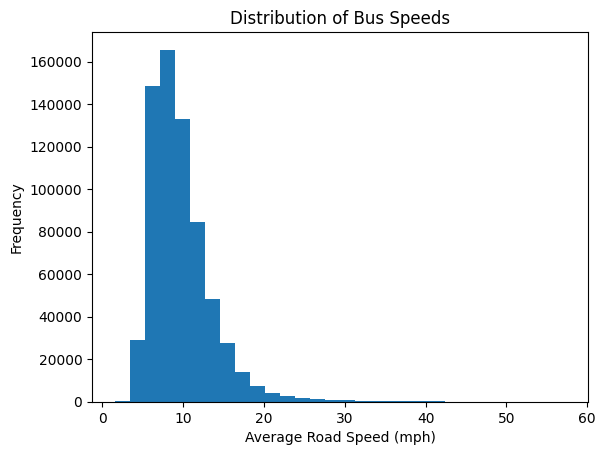

In [ ]:
plt.hist(df["Average Road Speed"], bins=30)

plt.title("Distribution of Bus Speeds")
plt.xlabel("Average Road Speed (mph)")
plt.ylabel("Frequency")

plt.show()

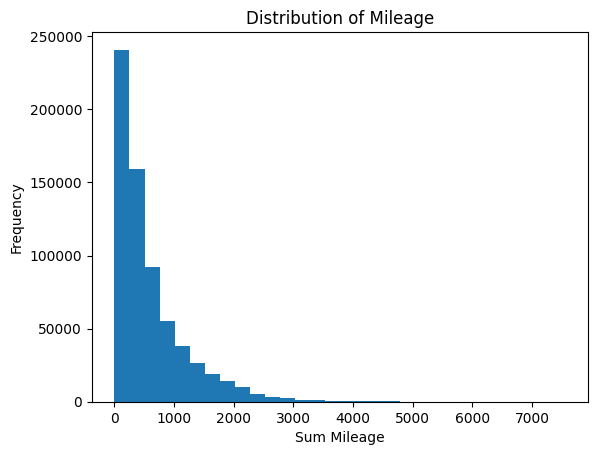

In [ ]:
plt.hist(df["Sum Mileage"], bins=30)

plt.title("Distribution of Mileage")
plt.xlabel("Sum Mileage")
plt.ylabel("Frequency")

plt.show()

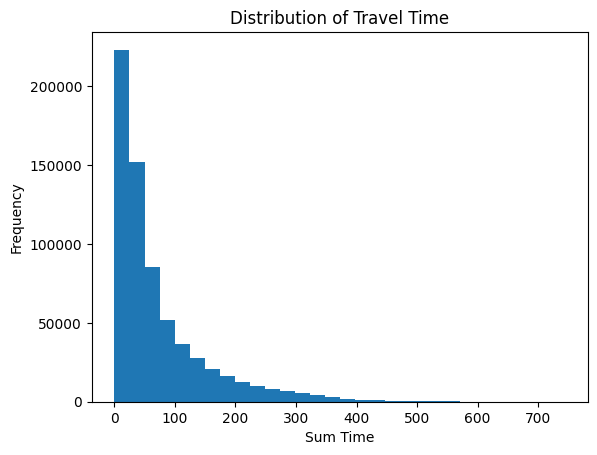

In [ ]:
plt.hist(df["Sum Time"], bins=30)

plt.title("Distribution of Travel Time")
plt.xlabel("Sum Time")
plt.ylabel("Frequency")

plt.show()

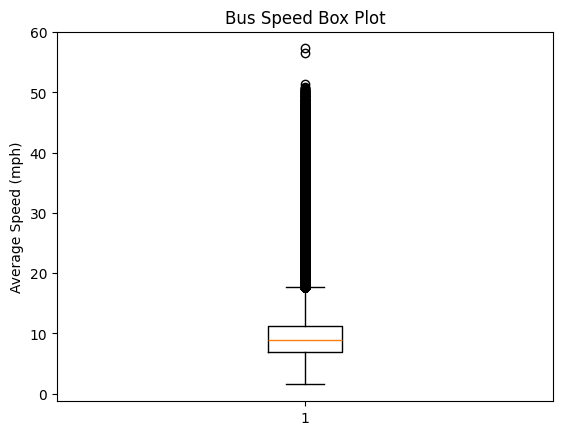

In [ ]:
plt.boxplot(df["Average Road Speed"])

plt.title("Bus Speed Box Plot")
plt.ylabel("Average Speed (mph)")

plt.show()

In [ ]:
# labeling each row as fast (1) if speed is 10 mph or more, otherwise slow (0)
df["Speed Category"] = (df["Average Road Speed"] >= 10).astype(int)

df["Speed Category"].value_counts()

,count
Speed Category,
0,422286
1,248462


## Model Training & Experimentation

**Regression Problem Statement: Predicting the average speed of a bus based on the given route information**

In [ ]:
# only using columns known ahead of time (mileage and time would give away the speed)
from sklearn.model_selection import train_test_split

features = ["Hour of Day", "Day Type", "Route Type", "CBD Relation"]

# turn text categories into 0/1 columns so the models can use them
X = pd.get_dummies(df[features], dtype=int)

y_reg = df["Average Road Speed"]
y_clf = df["Speed Category"]

X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# stratify keeps the fast/slow ratio the same in train and test
X_train_clf, X_test_clf, y_clf_train, y_clf_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (536598, 11)
Testing: (134150, 11)


In [ ]:
# baseline linear model to compare the tree against
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train, y_reg_train)

linear_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(mean_squared_error(y_reg_test, linear_pred))
linear_r2 = r2_score(y_reg_test, linear_pred)

print("Linear Regression Results")
print("RMSE:", round(linear_rmse, 2))
print("R2 Score:", round(linear_r2, 2))


Linear Regression Results
RMSE: 3.24
R2 Score: 0.31


In [ ]:
# decision tree with max_depth=5 to see if it beats the linear model
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train, y_reg_train)

tree_pred = tree_model.predict(X_test)

tree_rmse = np.sqrt(mean_squared_error(y_reg_test, tree_pred))
tree_r2 = r2_score(y_reg_test, tree_pred)

print("Decision Tree Results")
print("RMSE:", round(tree_rmse, 2))
print("R2 Score:", round(tree_r2, 2))

Decision Tree Results
RMSE: 2.75
R2 Score: 0.51


In [ ]:
# compare train vs test error at each depth to check for overfitting
depths = [2, 5, 10, 15, 20]

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_reg_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_reg_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_reg_test, test_pred))

    print("Depth:", depth,
          " Train RMSE:", round(train_rmse, 2),
          " Test RMSE:", round(test_rmse, 2))

Depth: 2  Train RMSE: 3.07  Test RMSE: 3.1
Depth: 5  Train RMSE: 2.74  Test RMSE: 2.75
Depth: 10  Train RMSE: 2.62  Test RMSE: 2.62
Depth: 15  Train RMSE: 2.62  Test RMSE: 2.62
Depth: 20  Train RMSE: 2.62  Test RMSE: 2.62


In [ ]:
# trying different polynomial degrees on Hour of Day to see which curve predicts speed best
from sklearn.preprocessing import PolynomialFeatures

X_poly = df[["Hour of Day"]]
y_poly = df["Average Road Speed"]

X_poly_train, X_poly_test, y_poly_train, y_poly_test = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=42
)

degrees = [1, 2, 3, 5, 10]

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)
    X_train_new = poly.fit_transform(X_poly_train)
    X_test_new = poly.transform(X_poly_test)

    model = LinearRegression()
    model.fit(X_train_new, y_poly_train)

    predictions = model.predict(X_test_new)
    rmse = np.sqrt(mean_squared_error(y_poly_test, predictions))

    print("Degree:", degree, " RMSE:", round(rmse, 2))

Degree: 1  RMSE: 3.86
Degree: 2  RMSE: 3.77
Degree: 3  RMSE: 3.75
Degree: 5  RMSE: 3.71
Degree: 10  RMSE: 3.72


**Classification Problem Statement: Predicting whether a bus will be fast or slow**

In [ ]:
# logistic regression to predict if a bus is fast (1) or slow (0)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_clf, y_clf_train)

logistic_pred = logistic_model.predict(X_test_clf)
logistic_accuracy = accuracy_score(y_clf_test, logistic_pred)

print("Logistic Regression Results")
print("Accuracy:", round(logistic_accuracy, 2))
print(classification_report(y_clf_test, logistic_pred))

Logistic Regression Results
Accuracy: 0.75
              precision    recall  f1-score   support

           0       0.75      0.92      0.82     84457
           1       0.77      0.47      0.58     49693

    accuracy                           0.75    134150
   macro avg       0.76      0.69      0.70    134150
weighted avg       0.76      0.75      0.73    134150



In [ ]:
# decision tree to predict fast vs slow, compared against logistic regression
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(max_depth=5, random_state=42)

tree_clf.fit(X_train_clf, y_clf_train)
tree_clf_pred = tree_clf.predict(X_test_clf)
tree_clf_accuracy = accuracy_score(y_clf_test, tree_clf_pred)

print("Decision Tree Classification Results")
print("Accuracy:", round(tree_clf_accuracy, 2))
print(classification_report(y_clf_test, tree_clf_pred))

Decision Tree Classification Results
Accuracy: 0.79
              precision    recall  f1-score   support

           0       0.80      0.88      0.84     84457
           1       0.76      0.62      0.69     49693

    accuracy                           0.79    134150
   macro avg       0.78      0.75      0.76    134150
weighted avg       0.78      0.79      0.78    134150



In [ ]:
# changing the cutoff for calling a bus fast to see how it affects catching slow buses
from sklearn.metrics import recall_score

probabilities = logistic_model.predict_proba(X_test_clf)[:, 1]

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    predictions = (probabilities >= threshold).astype(int)

    accuracy = accuracy_score(y_clf_test, predictions)
    recall = recall_score(y_clf_test, predictions, pos_label=0)

    print("Threshold:", threshold,
          " Accuracy:", round(accuracy, 2),
          " Low-speed Recall:", round(recall, 2))

Threshold: 0.3  Accuracy: 0.7  Low-speed Recall: 0.66
Threshold: 0.5  Accuracy: 0.75  Low-speed Recall: 0.92
Threshold: 0.7  Accuracy: 0.73  Low-speed Recall: 0.96


In [ ]:
# clustering hours and speeds into groups with different K values, using silhouette score to compare them
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 5000 rows because silhouette score is slow on the full data
cluster_data = df[["Hour of Day", "Average Road Speed"]].dropna()
cluster_data = cluster_data.sample(n=5000, random_state=42)

# K-Means uses distance, so both columns need the same scale
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

for k in [2, 3, 4, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(cluster_scaled)
    score = silhouette_score(cluster_scaled, labels)

    print("K:", k, " Silhouette Score:", round(score, 3))

K: 2  Silhouette Score: 0.411
K: 3  Silhouette Score: 0.43
K: 4  Silhouette Score: 0.383
K: 5  Silhouette Score: 0.391


In [ ]:
# changing DBSCAN's eps to see how the number of clusters and noise points changes
from sklearn.cluster import DBSCAN

eps_values = [0.2, 0.3, 0.5, 0.7]

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(cluster_scaled)

    clusters = len(set(labels) - {-1})
    noise = np.sum(labels == -1)

    print("Eps:", eps,
          " Clusters:", clusters,
          " Noise Points:", noise)

Eps: 0.2  Clusters: 3  Noise Points: 139
Eps: 0.3  Clusters: 1  Noise Points: 90
Eps: 0.5  Clusters: 2  Noise Points: 29
Eps: 0.7  Clusters: 2  Noise Points: 12


In [ ]:
# depth-10 tree with all features, for comparison
full_model = DecisionTreeRegressor(max_depth=10, random_state=42)
full_model.fit(X_train, y_reg_train)
full_rmse = np.sqrt(mean_squared_error(y_reg_test, full_model.predict(X_test)))

print("With Hour of Day")
print("RMSE:", round(full_rmse, 2))

With Hour of Day
RMSE: 2.62


In [ ]:
# dropping Hour of Day to see how much worse the tree gets without it
X_less = X.drop(columns=["Hour of Day"])

X_less_train, X_less_test, y_less_train, y_less_test = train_test_split(
    X_less, y_reg, test_size=0.2, random_state=42
)

less_model = DecisionTreeRegressor(max_depth=10, random_state=42)
less_model.fit(X_less_train, y_less_train)

less_pred = less_model.predict(X_less_test)
less_rmse = np.sqrt(mean_squared_error(y_less_test, less_pred))

print("Without Hour of Day")
print("RMSE:", round(less_rmse, 2))

Without Hour of Day
RMSE: 3.26
